<a href="https://colab.research.google.com/github/meedooatef22/arabic-dialect-classification/blob/main/notebooks/03_Baseline_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Load Train, Validation, and Test Splits & Verify Integrity

In [1]:
from google.colab import drive
import pandas as pd
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define path to processed splits
processed_dir = '/content/drive/MyDrive/arabic-dialect-classification/data/processed'

# 3. Load the three datasets
train_df = pd.read_csv(os.path.join(processed_dir, 'train.csv'))
val_df = pd.read_csv(os.path.join(processed_dir, 'val.csv'))
test_df = pd.read_csv(os.path.join(processed_dir, 'test.csv'))

# 4. Sanity check: Shapes and Missing Values (NaN)
print("Dataset Shapes & Missing Values Check:")
for name, dataset in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    null_count = dataset.isnull().sum().sum()
    print(f"- {name:10s} | Shape: {dataset.shape} | Total Nulls: {null_count}")

# 5. Display first 3 rows of the training set
print("\nSample from Training Set:")
display(train_df.head(3))

Mounted at /content/drive
Dataset Shapes & Missing Values Check:
- Train      | Shape: (46732, 2) | Total Nulls: 0
- Validation | Shape: (5841, 2) | Total Nulls: 0
- Test       | Shape: (5842, 2) | Total Nulls: 0

Sample from Training Set:


,cleaned_text,label
0,شكرا علي العشاء الرائع,MSA
1,ابغي نموذج قيمه الضريبه المضافه من فضلك,MSA
2,ممكن اكمل رحلتي,Cairo


### Step 2: Vocabulary & N-Gram Exploration (Before TF-IDF Configuration)

In [2]:
from sklearn.feature_extraction.text import CountVectorizer

# 1. Check total unique single words (Unigrams)
unigram_vec = CountVectorizer(ngram_range=(1, 1))
X_unigrams = unigram_vec.fit_transform(train_df['cleaned_text'])
unigram_counts = X_unigrams.sum(axis=0).A1

# 2. Check total unique word pairs (Unigrams + Bigrams)
bigram_vec = CountVectorizer(ngram_range=(1, 2))
X_bigrams = bigram_vec.fit_transform(train_df['cleaned_text'])
bigram_counts = X_bigrams.sum(axis=0).A1

print(f"Total unique words (Unigrams only) in Train set        : {len(unigram_counts):,}")
print(f"Words appearing ONLY ONCE (rare/typos)                 : {(unigram_counts == 1).sum():,} ({(unigram_counts == 1).mean()*100:.1f}%)")
print(f"Words appearing at least 2 times (min_df=2)            : {(unigram_counts >= 2).sum():,}")
print(f"Words appearing at least 3 times (min_df=3)            : {(unigram_counts >= 3).sum():,}")
print("-" * 65)
print(f"Total features with Unigrams + Bigrams (1, 2)          : {len(bigram_counts):,}")
print(f"Unigrams + Bigrams appearing at least 2 times (min_df=2): {(bigram_counts >= 2).sum():,}")
print(f"Unigrams + Bigrams appearing at least 3 times (min_df=3): {(bigram_counts >= 3).sum():,}")

Total unique words (Unigrams only) in Train set        : 33,011
Words appearing ONLY ONCE (rare/typos)                 : 17,360 (52.6%)
Words appearing at least 2 times (min_df=2)            : 15,651
Words appearing at least 3 times (min_df=3)            : 10,793
-----------------------------------------------------------------
Total features with Unigrams + Bigrams (1, 2)          : 171,664
Unigrams + Bigrams appearing at least 2 times (min_df=2): 41,694
Unigrams + Bigrams appearing at least 3 times (min_df=3): 22,640


### Step 2.1: Vocabulary Analysis Insights & TF-IDF Configuration Decision

**1. Observation:**
* **High Sparsity in Unigrams:** Out of **33,011** unique words in the training set, **17,360 words (52.6%)** appear **only once** (`hapax legomena`). In dialectal Arabic, this is largely due to non-standardized spelling variations and rare proper nouns.
* **Bigram Explosion:** Including bigrams (`ngram_range=(1, 2)`) expands the feature space to **171,664** features, the vast majority of which are single-occurrence word pairs that introduce noise and risk overfitting.
* **Effect of Frequency Thresholding:** Setting a minimum document frequency of 2 (`min_df=2`) prunes noisy single-occurrence terms and reduces the feature space by **~75%** (from 171,664 down to a clean, informative **41,694** features).

**2. Engineering Decision:**
We configure our `TfidfVectorizer` with:
* `ngram_range=(1, 2)` to capture both lexical markers (unigrams) and local dialectal phrases (bigrams).
* `min_df=2` to eliminate the 52.6% single-occurrence noise identified above.
* `sublinear_tf=True` to apply logarithmic scaling to term frequencies.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Initialize TF-IDF Vectorizer based on our empirical findings
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# 2. Fit ONLY on the training data, then transform Train, Val, and Test
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['cleaned_text'])
X_val_tfidf = tfidf_vectorizer.transform(val_df['cleaned_text'])
X_test_tfidf = tfidf_vectorizer.transform(test_df['cleaned_text'])

y_train = train_df['label']
y_val = val_df['label']
y_test = test_df['label']

# 3. Verify the resulting feature matrix shapes
print(f"X_train_tfidf shape: {X_train_tfidf.shape}")
print(f"X_val_tfidf shape  : {X_val_tfidf.shape}")
print(f"X_test_tfidf shape : {X_test_tfidf.shape}")

X_train_tfidf shape: (46732, 41585)
X_val_tfidf shape  : (5841, 41585)
X_test_tfidf shape : (5842, 41585)


### Step 3: Train and Compare Classical ML Baseline Models on Validation Set

In [4]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import time

# 1. Define the 3 candidate baseline models with default hyperparameters
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVC": LinearSVC(random_state=42)
}

# 2. Train each model and evaluate on both Train and Validation sets to inspect overfitting
results = []

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train_tfidf, y_train)
    train_time = time.time() - start_time

    # Predictions on Train and Validation
    y_train_pred = model.predict(X_train_tfidf)
    y_val_pred = model.predict(X_val_tfidf)

    # Calculate Accuracy and Macro F1-Score
    train_acc = accuracy_score(y_train, y_train_pred) * 100
    val_acc = accuracy_score(y_val, y_val_pred) * 100
    val_f1 = f1_score(y_val, y_val_pred, average='macro') * 100

    results.append({
        "Model": name,
        "Train Accuracy (%)": round(train_acc, 2),
        "Val Accuracy (%)": round(val_acc, 2),
        "Val Macro F1 (%)": round(val_f1, 2),
        "Overfit Gap (%)": round(train_acc - val_acc, 2),
        "Training Time (s)": round(train_time, 2)
    })

# 3. Display comparison table sorted by Validation Macro F1
results_df = pd.DataFrame(results).sort_values(by="Val Macro F1 (%)", ascending=False).reset_index(drop=True)
print("Baseline Models Comparison on Validation Set:")
display(results_df)

Baseline Models Comparison on Validation Set:


,Model,Train Accuracy (%),Val Accuracy (%),Val Macro F1 (%),Overfit Gap (%),Training Time (s)
0,Multinomial Naive Bayes,95.54,90.17,90.15,5.37,0.32
1,Logistic Regression,96.20,89.01,89.00,7.19,15.46
2,Linear SVC,98.71,88.99,88.97,9.72,4.37


### Step 3.1: Diagnosis of Baseline Results & Overfitting Analysis

**1. Observation:**
* **`Multinomial Naive Bayes`** achieved the highest validation performance (**90.17% Accuracy / 90.15% Macro F1**) in just **0.32 seconds**, while maintaining the lowest overfitting gap (**5.37%**).
* **`Linear SVC`** achieved the highest training accuracy (**98.71%**), but suffered from the largest overfitting gap (**9.72%**), dropping to **88.99%** on the validation set.
* **`Logistic Regression`** showed moderate overfitting (**7.19% gap**) with **89.01%** validation accuracy.

**2. Root Cause & Corrective Action (Targeted Hyperparameter Tuning):**
In high-dimensional sparse text matrices (41,585 TF-IDF features), linear discriminators (`LinearSVC` and `LogisticRegression`) with the default regularization parameter (`C=1.0`) tend to overfit to specific bigrams in the training set.
* We will test stronger regularization (**smaller `C` values**: `0.1`, `0.25`, `0.5`, `1.0`) for `LinearSVC` and `LogisticRegression` to reduce the overfitting gap.
* We will also tune the Laplace smoothing parameter (**`alpha`**: `0.1`, `0.3`, `0.5`, `0.7`, `1.0`) for `MultinomialNB` to see if validation accuracy can be pushed even higher.

In [5]:
tuning_results = []

# 1. Tune Multinomial Naive Bayes (alpha)
for alpha_val in [0.1, 0.3, 0.5, 0.7, 1.0]:
    mnb = MultinomialNB(alpha=alpha_val)
    mnb.fit(X_train_tfidf, y_train)
    train_acc = accuracy_score(y_train, mnb.predict(X_train_tfidf)) * 100
    val_pred = mnb.predict(X_val_tfidf)
    val_acc = accuracy_score(y_val, val_pred) * 100
    val_f1 = f1_score(y_val, val_pred, average='macro') * 100
    tuning_results.append({
        "Model": "Multinomial NB", "Param": f"alpha={alpha_val}",
        "Train Acc (%)": round(train_acc, 2), "Val Acc (%)": round(val_acc, 2),
        "Val Macro F1 (%)": round(val_f1, 2), "Overfit Gap (%)": round(train_acc - val_acc, 2)
    })

# 2. Tune Linear SVC (C - lower C means stronger regularization against overfitting)
for c_val in [0.1, 0.25, 0.5, 1.0]:
    svc = LinearSVC(C=c_val, random_state=42)
    svc.fit(X_train_tfidf, y_train)
    train_acc = accuracy_score(y_train, svc.predict(X_train_tfidf)) * 100
    val_pred = svc.predict(X_val_tfidf)
    val_acc = accuracy_score(y_val, val_pred) * 100
    val_f1 = f1_score(y_val, val_pred, average='macro') * 100
    tuning_results.append({
        "Model": "Linear SVC", "Param": f"C={c_val}",
        "Train Acc (%)": round(train_acc, 2), "Val Acc (%)": round(val_acc, 2),
        "Val Macro F1 (%)": round(val_f1, 2), "Overfit Gap (%)": round(train_acc - val_acc, 2)
    })

# 3. Tune Logistic Regression (C)
for c_val in [0.5, 1.0, 2.0]:
    lr = LogisticRegression(C=c_val, max_iter=1000, random_state=42)
    lr.fit(X_train_tfidf, y_train)
    train_acc = accuracy_score(y_train, lr.predict(X_train_tfidf)) * 100
    val_pred = lr.predict(X_val_tfidf)
    val_acc = accuracy_score(y_val, val_pred) * 100
    val_f1 = f1_score(y_val, val_pred, average='macro') * 100
    tuning_results.append({
        "Model": "Logistic Regression", "Param": f"C={c_val}",
        "Train Acc (%)": round(train_acc, 2), "Val Acc (%)": round(val_acc, 2),
        "Val Macro F1 (%)": round(val_f1, 2), "Overfit Gap (%)": round(train_acc - val_acc, 2)
    })

# Display sorted tuning results
tuning_df = pd.DataFrame(tuning_results).sort_values(by="Val Macro F1 (%)", ascending=False).reset_index(drop=True)
print("Hyperparameter Tuning Results (Sorted by Validation Macro F1):")
display(tuning_df)

Hyperparameter Tuning Results (Sorted by Validation Macro F1):


,Model,Param,Train Acc (%),Val Acc (%),Val Macro F1 (%),Overfit Gap (%)
0,Multinomial NB,alpha=1.0,95.54,90.17,90.15,5.37
1,Multinomial NB,alpha=0.7,95.84,90.17,90.14,5.67
2,Multinomial NB,alpha=0.5,96.07,90.12,90.09,5.95
3,Multinomial NB,alpha=0.3,96.29,89.88,89.85,6.41
4,Linear SVC,C=0.25,97.42,89.39,89.38,8.03
5,Logistic Regression,C=2.0,97.58,89.20,89.20,8.38
6,Linear SVC,C=0.5,98.24,89.16,89.16,9.08
7,Multinomial NB,alpha=0.1,96.63,89.15,89.11,7.49
8,Logistic Regression,C=1.0,96.20,89.01,89.00,7.19
9,Linear SVC,C=0.1,95.56,88.99,88.98,6.56


### Step 4: Final Evaluation of Best Baseline Model (`MultinomialNB`, `alpha=1.0`) on Test Set

**1. Tuning Conclusion:**
* Stronger regularization (`C=0.25`) successfully improved `LinearSVC` validation accuracy from **88.99%** to **89.39%** while reducing its overfitting gap from **9.72%** to **8.03%**.
* However, **`Multinomial Naive Bayes` (`alpha=1.0`)** remains the top-performing baseline model overall, achieving **90.17% Validation Accuracy (90.15% Macro F1)** with the lowest overfitting gap (**5.37%**). Decreasing `alpha` below `1.0` increased overfitting without improving validation metrics.

**2. Final Benchmark Evaluation:**
We now select `MultinomialNB(alpha=1.0)` as our official classical ML baseline and evaluate it on the held-out **Test Set** (5,842 unseen sentences), examining the per-dialect classification report and confusion matrix.

Official Baseline Test Accuracy : 89.85%
Official Baseline Test Macro F1 : 89.82%

Detailed Classification Report per Dialect (Test Set):
              precision    recall  f1-score   support

      Beirut     0.9241    0.8774    0.9001      1166
       Cairo     0.8605    0.8780    0.8691      1180
        Doha     0.8868    0.8687    0.8776      1127
         MSA     0.9134    0.9483    0.9305      1179
       Tunis     0.9086    0.9185    0.9135      1190

    accuracy                         0.8985      5842
   macro avg     0.8987    0.8982    0.8982      5842
weighted avg     0.8987    0.8985    0.8984      5842



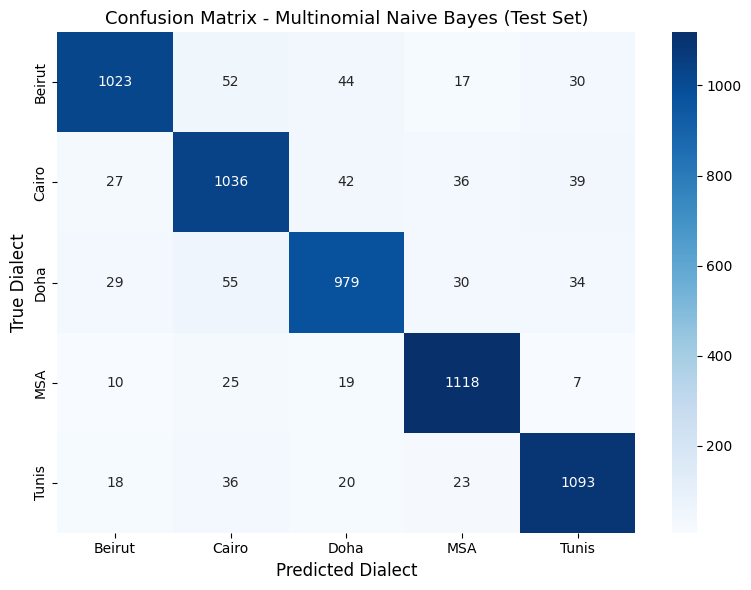

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Train the winning baseline model
best_baseline = MultinomialNB(alpha=1.0)
best_baseline.fit(X_train_tfidf, y_train)

# 2. Predict on the unseen Test Set
y_test_pred = best_baseline.predict(X_test_tfidf)

# 3. Print overall Test metrics and detailed Classification Report
test_acc = accuracy_score(y_test, y_test_pred) * 100
test_f1 = f1_score(y_test, y_test_pred, average='macro') * 100

print(f"Official Baseline Test Accuracy : {test_acc:.2f}%")
print(f"Official Baseline Test Macro F1 : {test_f1:.2f}%\n")
print("Detailed Classification Report per Dialect (Test Set):")
print(classification_report(y_test, y_test_pred, digits=4))

# 4. Plot Confusion Matrix to inspect where the model makes mistakes
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_test_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - Multinomial Naive Bayes (Test Set)', fontsize=13)
plt.xlabel('Predicted Dialect', fontsize=12)
plt.ylabel('True Dialect', fontsize=12)
plt.tight_layout()
plt.show()

### Step 4.1: Error Analysis — Inspecting Misclassified Sentences

In [7]:
# Create a DataFrame comparing True vs Predicted labels on the Test Set
error_df = test_df.copy()
error_df['predicted_label'] = y_test_pred
error_df['word_count'] = error_df['cleaned_text'].apply(lambda x: len(str(x).split()))

# Filter only misclassified rows
mistakes_df = error_df[error_df['label'] != error_df['predicted_label']]
print(f"Total misclassified sentences out of {len(test_df)}: {len(mistakes_df)} ({len(mistakes_df)/len(test_df)*100:.2f}%)\n")

# 1. Inspect average sentence length: Correct vs. Misclassified
correct_df = error_df[error_df['label'] == error_df['predicted_label']]
print(f"Average word count of CORRECT predictions      : {correct_df['word_count'].mean():.2f} words")
print(f"Average word count of MISCLASSIFIED predictions: {mistakes_df['word_count'].mean():.2f} words")
print("-" * 70)

# 2. Display sample mistakes where Doha or Beirut was misclassified as Cairo
print("\nSample Sentences where True is 'Doha' or 'Beirut' but Predicted as 'Cairo':")
doha_beirut_as_cairo = mistakes_df[
    (mistakes_df['label'].isin(['Doha', 'Beirut'])) &
    (mistakes_df['predicted_label'] == 'Cairo')
]
display(doha_beirut_as_cairo[['cleaned_text', 'label', 'predicted_label', 'word_count']].head(12))

Total misclassified sentences out of 5842: 593 (10.15%)

Average word count of CORRECT predictions      : 5.92 words
Average word count of MISCLASSIFIED predictions: 4.21 words
----------------------------------------------------------------------

Sample Sentences where True is 'Doha' or 'Beirut' but Predicted as 'Cairo':


,cleaned_text,label,predicted_label,word_count
10,شورايك بعشره دولار للتلاته,Beirut,Cairo,4
66,هي اوتوماتيك,Doha,Cairo,2
77,خليني اقرا الرقم حسب الشكل واحد صفر فاصله سبعه...,Beirut,Cairo,11
97,ممكن تشيل البقع من هالثياب,Doha,Cairo,5
158,هو حرامي,Doha,Cairo,2
253,انا بس مار,Doha,Cairo,3
342,ممكن ادفع بجيك سياحي,Doha,Cairo,4
441,سنه جديده سعيده,Beirut,Cairo,3
547,ممكن تسال عند مكتب الاستعلامات هناك اذا ضيعت,Doha,Cairo,8
611,عندك اي معلومات عن الانشطه الترفيهيه في المدين...,Doha,Cairo,9


### Step 4.2: Key Insights from Error Analysis & Motivation for Deep Learning (Transformers)

**1. Why Misclassifications Occur (Empirical Findings):**
* **Short Context Penalty:** Misclassified sentences are significantly shorter (**4.21 words** on average) compared to correctly classified ones (**5.92 words**), providing fewer lexical cues.
* **Dialect-Neutral Overlap:** Ultra-short phrases like `هي اوتوماتيك`, `هو حرامي`, and `سنه جديده سعيده` are identical across Cairo, Beirut, and Doha in written form.
* **Word-Level TF-IDF Limitation (Morphological Blindness):** In sentences like `ممكن تشيل البقع من هالثياب` (Doha) and `انا ماشي فاصرف لي هالفيش لو سمحت` (Doha), the model misclassified them as `Cairo` because high-frequency Egyptian words (`ممكن`, `ماشي`, `تشيل`) outweighed rare compound surface forms (`هالثياب`, `هالفيش`). Because word-level TF-IDF treats `هالثياب` as a single isolated token rather than recognizing the Gulf/Levantine prefix **`هالـ` (`hal-`)**, it misses crucial subword morphological markers. Similarly, attached spellings like `شورايك` (Beirut) obscure the token `شو`.

**2. How This Motivates Our Next Phase (Pre-trained Arabic Transformers):**
To overcome word-level blindness and context limitations, our next phase will leverage subword tokenization (**WordPiece** in `AraBERT` / `MARBERT`), which automatically splits `هالثياب` into `هال + ثياب` and `شورايك` into `شو + رايك`, while utilizing self-attention to evaluate the full sentence context.

### Step 4.2: Improving the Baseline via Error-Driven Feature Engineering (Word + Character N-Grams)

**1. Diagnostic Insight from Error Analysis:**
Inspecting the misclassified sentences revealed that word-level `TF-IDF` misses subword dialectal prefixes/suffixes when attached to words, such as **`هالـ`** in `هالثياب` / `هالفيش` (Doha) or **`شو`** in `شورايك` (Beirut), allowing common words like `ممكن` (Cairo) to dominate the prediction.

**2. Engineering Solution (`FeatureUnion`):**
Before moving to Deep Learning, we can directly address this morphological blindness in our classical pipeline by combining:
* **Word N-grams `(1, 2)`:** Captures full words and multi-word phrases.
* **Character N-grams `(3, 5)` (`analyzer='char_wb'`):** Extracts character sequences within word boundaries, enabling the classical model to detect subword prefixes (`هال`, `شو`, `عاي`, `بد`) even in unseen or attached word forms.

In [8]:
from sklearn.pipeline import FeatureUnion

# 1. Combine Word N-grams (1,2) and Subword Character N-grams (3,5)
combined_vectorizer = FeatureUnion([
    ('word_tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('char_tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5, sublinear_tf=True))
])

print("Extracting combined Word + Character N-gram features...")
X_train_combined = combined_vectorizer.fit_transform(train_df['cleaned_text'])
X_val_combined = combined_vectorizer.transform(val_df['cleaned_text'])
X_test_combined = combined_vectorizer.transform(test_df['cleaned_text'])

print(f"Combined Feature Matrix Shape: {X_train_combined.shape}\n")

# 2. Evaluate our top models on the enriched feature space (Validation Set)
improved_results = []

for name, model in [
    ("Multinomial NB (alpha=0.5)", MultinomialNB(alpha=0.5)),
    ("Multinomial NB (alpha=1.0)", MultinomialNB(alpha=1.0)),
    ("Linear SVC (C=0.25)", LinearSVC(C=0.25, random_state=42)),
    ("Logistic Regression (C=1.0)", LogisticRegression(C=1.0, max_iter=1000, random_state=42))
]:
    model.fit(X_train_combined, y_train)
    val_pred = model.predict(X_val_combined)
    val_acc = accuracy_score(y_val, val_pred) * 100
    val_f1 = f1_score(y_val, val_pred, average='macro') * 100

    improved_results.append({
        "Model (Word + Char N-grams)": name,
        "Val Accuracy (%)": round(val_acc, 2),
        "Val Macro F1 (%)": round(val_f1, 2),
        "Improvement over Old Best (+%)": round(val_acc - 90.17, 2)
    })

improved_df = pd.DataFrame(improved_results).sort_values(by="Val Macro F1 (%)", ascending=False).reset_index(drop=True)
display(improved_df)

Extracting combined Word + Character N-gram features...
Combined Feature Matrix Shape: (46732, 82062)



,Model (Word + Char N-grams),Val Accuracy (%),Val Macro F1 (%),Improvement over Old Best (+%)
0,Multinomial NB (alpha=0.5),91.08,91.06,0.91
1,Linear SVC (C=0.25),90.91,90.90,0.74
2,Multinomial NB (alpha=1.0),90.74,90.72,0.57
3,Logistic Regression (C=1.0),90.69,90.67,0.52


### Step 4.3: Final Test Evaluation of Improved Baseline & Verification on Previously Misclassified Sentences

Old Baseline Test Accuracy (Word-only)         : 89.85%
Improved Baseline Test Accuracy (Word + Char)  : 90.31% (+0.46%)
Improved Baseline Test Macro F1                : 90.28%

Detailed Classification Report (Improved Baseline - Test Set):
              precision    recall  f1-score   support

      Beirut     0.9123    0.8834    0.8976      1166
       Cairo     0.8733    0.8822    0.8777      1180
        Doha     0.8891    0.8820    0.8855      1127
         MSA     0.9117    0.9457    0.9284      1179
       Tunis     0.9288    0.9210    0.9249      1190

    accuracy                         0.9031      5842
   macro avg     0.9030    0.9029    0.9028      5842
weighted avg     0.9032    0.9031    0.9030      5842



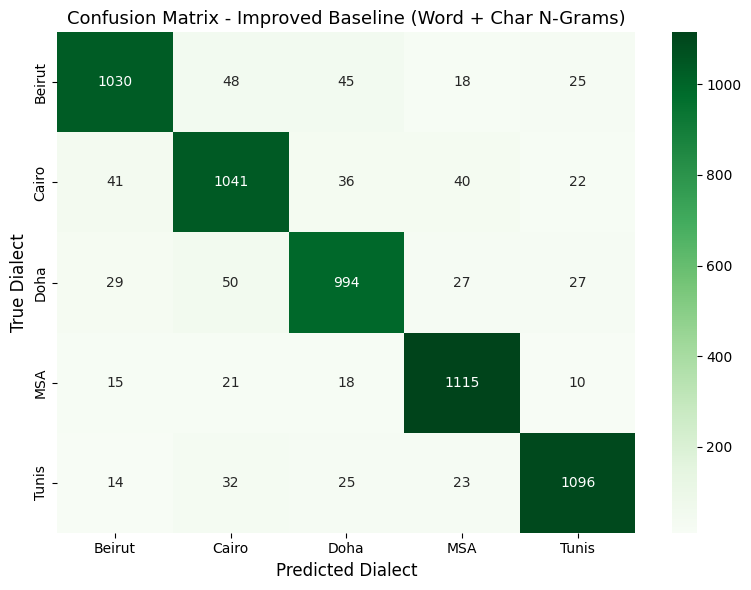


Verification on Previously Misclassified Sentences:


,cleaned_text,label,Old_Pred (Word Only),New_Pred (Word + Char),Fixed?
10,شورايك بعشره دولار للتلاته,Beirut,Cairo,Cairo,False
66,هي اوتوماتيك,Doha,Cairo,Cairo,False
77,خليني اقرا الرقم حسب الشكل واحد صفر فاصله سبعه...,Beirut,Cairo,Cairo,False
97,ممكن تشيل البقع من هالثياب,Doha,Cairo,Doha,True
158,هو حرامي,Doha,Cairo,Cairo,False
253,انا بس مار,Doha,Cairo,Cairo,False
342,ممكن ادفع بجيك سياحي,Doha,Cairo,Doha,True
441,سنه جديده سعيده,Beirut,Cairo,Cairo,False
547,ممكن تسال عند مكتب الاستعلامات هناك اذا ضيعت,Doha,Cairo,Doha,True
611,عندك اي معلومات عن الانشطه الترفيهيه في المدين...,Doha,Cairo,Beirut,False


In [9]:
# 1. Train the winning improved baseline model: MultinomialNB(alpha=0.5) on Combined Features
best_improved_baseline = MultinomialNB(alpha=0.5)
best_improved_baseline.fit(X_train_combined, y_train)

# 2. Predict on the unseen Test Set
y_test_pred_improved = best_improved_baseline.predict(X_test_combined)

test_acc_imp = accuracy_score(y_test, y_test_pred_improved) * 100
test_f1_imp = f1_score(y_test, y_test_pred_improved, average='macro') * 100

print(f"Old Baseline Test Accuracy (Word-only)         : {test_acc:.2f}%")
print(f"Improved Baseline Test Accuracy (Word + Char)  : {test_acc_imp:.2f}% (+{test_acc_imp - test_acc:.2f}%)")
print(f"Improved Baseline Test Macro F1                : {test_f1_imp:.2f}%\n")

print("Detailed Classification Report (Improved Baseline - Test Set):")
print(classification_report(y_test, y_test_pred_improved, digits=4))

# 3. Plot the Updated Confusion Matrix
labels = sorted(y_test.unique())
cm_imp = confusion_matrix(y_test, y_test_pred_improved, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_imp, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - Improved Baseline (Word + Char N-Grams)', fontsize=13)
plt.xlabel('Predicted Dialect', fontsize=12)
plt.ylabel('True Dialect', fontsize=12)
plt.tight_layout()
plt.show()

# 4. Check what happened to the exact 12 sentences that were previously misclassified!
comparison_df = test_df.loc[doha_beirut_as_cairo.head(12).index, ['cleaned_text', 'label']].copy()
comparison_df['Old_Pred (Word Only)'] = y_test_pred[doha_beirut_as_cairo.head(12).index]
comparison_df['New_Pred (Word + Char)'] = y_test_pred_improved[doha_beirut_as_cairo.head(12).index]
comparison_df['Fixed?'] = comparison_df['label'] == comparison_df['New_Pred (Word + Char)']

print("\nVerification on Previously Misclassified Sentences:")
display(comparison_df)

### Step 4.4: Pushing the Classical Limit — Refined Char N-Grams (2, 6) + Ensemble Voting Classifier

In [10]:
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV

# 1. Refine FeatureUnion: Expand char_wb to (2, 6) with min_df=3 to catch 2-letter prefixes (شو, هال, مو)
refined_vectorizer = FeatureUnion([
    ('word_tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('char_tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 6), min_df=3, sublinear_tf=True))
])

print("Extracting refined Word (1,2) + Char_wb (2,6) features...")
X_train_ref = refined_vectorizer.fit_transform(train_df['cleaned_text'])
X_val_ref = refined_vectorizer.transform(val_df['cleaned_text'])
X_test_ref = refined_vectorizer.transform(test_df['cleaned_text'])
print(f"Refined Feature Matrix Shape: {X_train_ref.shape}\n")

# 2. Build Soft Voting Ensemble combining our top 3 diverse models
# Note: Wrap LinearSVC in CalibratedClassifierCV so it outputs probabilities for Soft Voting
mnb_clf = MultinomialNB(alpha=0.5)
svc_clf = CalibratedClassifierCV(LinearSVC(C=0.3, random_state=42), cv=3)
lr_clf = LogisticRegression(C=1.5, max_iter=1000, random_state=42)

ensemble_model = VotingClassifier(
    estimators=[('mnb', mnb_clf), ('svc', svc_clf), ('lr', lr_clf)],
    voting='soft',
    weights=[2, 2, 1] # Give slightly higher weight to our top two performers (MNB & SVC)
)

print("Training Ensemble Model (MNB + Calibrated LinearSVC + LogisticRegression)...")
ensemble_model.fit(X_train_ref, y_train)

# 3. Evaluate on Validation and Test sets
val_pred_ens = ensemble_model.predict(X_val_ref)
test_pred_ens = ensemble_model.predict(X_test_ref)

val_acc_ens = accuracy_score(y_val, val_pred_ens) * 100
test_acc_ens = accuracy_score(y_test, test_pred_ens) * 100
test_f1_ens = f1_score(y_test, test_pred_ens, average='macro') * 100

print(f"Validation Accuracy (Ensemble) : {val_acc_ens:.2f}% (vs 91.08% previously)")
print(f"Test Accuracy (Ensemble)       : {test_acc_ens:.2f}% (vs 90.31% previously)")
print(f"Test Macro F1 (Ensemble)       : {test_f1_ens:.2f}%\n")

# 4. Check the 12 tricky sentences again!
comparison_df['Ensemble_Pred'] = test_pred_ens[doha_beirut_as_cairo.head(12).index]
comparison_df['Fixed_by_Ensemble?'] = comparison_df['label'] == comparison_df['Ensemble_Pred']
display(comparison_df[['cleaned_text', 'label', 'Old_Pred (Word Only)', 'New_Pred (Word + Char)', 'Ensemble_Pred', 'Fixed_by_Ensemble?']])

Extracting refined Word (1,2) + Char_wb (2,6) features...
Refined Feature Matrix Shape: (46732, 118491)

Training Ensemble Model (MNB + Calibrated LinearSVC + LogisticRegression)...
Validation Accuracy (Ensemble) : 91.41% (vs 91.08% previously)
Test Accuracy (Ensemble)       : 90.89% (vs 90.31% previously)
Test Macro F1 (Ensemble)       : 90.86%



,cleaned_text,label,Old_Pred (Word Only),New_Pred (Word + Char),Ensemble_Pred,Fixed_by_Ensemble?
10,شورايك بعشره دولار للتلاته,Beirut,Cairo,Cairo,Cairo,False
66,هي اوتوماتيك,Doha,Cairo,Cairo,Cairo,False
77,خليني اقرا الرقم حسب الشكل واحد صفر فاصله سبعه...,Beirut,Cairo,Cairo,Cairo,False
97,ممكن تشيل البقع من هالثياب,Doha,Cairo,Doha,Doha,True
158,هو حرامي,Doha,Cairo,Cairo,Cairo,False
253,انا بس مار,Doha,Cairo,Cairo,Cairo,False
342,ممكن ادفع بجيك سياحي,Doha,Cairo,Doha,Doha,True
441,سنه جديده سعيده,Beirut,Cairo,Cairo,Cairo,False
547,ممكن تسال عند مكتب الاستعلامات هناك اذا ضيعت,Doha,Cairo,Doha,Doha,True
611,عندك اي معلومات عن الانشطه الترفيهيه في المدين...,Doha,Cairo,Beirut,Beirut,False


### Step 4.5: Error-Correcting Meta-Learner (`StackingClassifier` + `ComplementNB`)

In [11]:
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import StackingClassifier

# 1. Define diverse base models (including ComplementNB which penalizes dominant-class bias like 'Cairo')
base_learners = [
    ('mnb', MultinomialNB(alpha=0.5)),
    ('cnb', ComplementNB(alpha=0.5)),
    ('svc', CalibratedClassifierCV(LinearSVC(C=0.3, random_state=42), cv=3)),
    ('lr', LogisticRegression(C=1.5, max_iter=1000, random_state=42))
]

# 2. Define the Meta-Learner (Final Estimator) that learns where each base model makes mistakes
meta_learner = LogisticRegression(C=1.0, max_iter=1000, random_state=42)

stacking_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=3,
    n_jobs=-1
)

print("Training Stacking Meta-Model (learning to correct base models' errors)...")
stacking_model.fit(X_train_ref, y_train)

# 3. Evaluate on Validation and Test sets
val_pred_stack = stacking_model.predict(X_val_ref)
test_pred_stack = stacking_model.predict(X_test_ref)

val_acc_stack = accuracy_score(y_val, val_pred_stack) * 100
test_acc_stack = accuracy_score(y_test, test_pred_stack) * 100
test_f1_stack = f1_score(y_test, test_pred_stack, average='macro') * 100

print(f"Validation Accuracy (Stacking) : {val_acc_stack:.2f}% (vs 91.41% Ensemble)")
print(f"Test Accuracy (Stacking)       : {test_acc_stack:.2f}% (vs 90.89% Ensemble)")
print(f"Test Macro F1 (Stacking)       : {test_f1_stack:.2f}%\n")

# 4. Inspect the 12 tricky sentences to see if Stacking fixed even more mistakes!
comparison_df['Stacking_Pred'] = test_pred_stack[doha_beirut_as_cairo.head(12).index]
comparison_df['Fixed_by_Stacking?'] = comparison_df['label'] == comparison_df['Stacking_Pred']
display(comparison_df[['cleaned_text', 'label', 'Old_Pred (Word Only)', 'Ensemble_Pred', 'Stacking_Pred', 'Fixed_by_Stacking?']])

Training Stacking Meta-Model (learning to correct base models' errors)...
Validation Accuracy (Stacking) : 91.51% (vs 91.41% Ensemble)
Test Accuracy (Stacking)       : 90.93% (vs 90.89% Ensemble)
Test Macro F1 (Stacking)       : 90.90%



,cleaned_text,label,Old_Pred (Word Only),Ensemble_Pred,Stacking_Pred,Fixed_by_Stacking?
10,شورايك بعشره دولار للتلاته,Beirut,Cairo,Cairo,Cairo,False
66,هي اوتوماتيك,Doha,Cairo,Cairo,Doha,True
77,خليني اقرا الرقم حسب الشكل واحد صفر فاصله سبعه...,Beirut,Cairo,Cairo,Cairo,False
97,ممكن تشيل البقع من هالثياب,Doha,Cairo,Doha,Doha,True
158,هو حرامي,Doha,Cairo,Cairo,Cairo,False
253,انا بس مار,Doha,Cairo,Cairo,Cairo,False
342,ممكن ادفع بجيك سياحي,Doha,Cairo,Doha,Doha,True
441,سنه جديده سعيده,Beirut,Cairo,Cairo,Cairo,False
547,ممكن تسال عند مكتب الاستعلامات هناك اذا ضيعت,Doha,Cairo,Doha,Doha,True
611,عندك اي معلومات عن الانشطه الترفيهيه في المدين...,Doha,Cairo,Beirut,Beirut,False


### Step 5: Save Final Champion Classical Model (`StackingClassifier`) & Live Inference Check

**1. Summary of Classical ML Progression:**
Through iterative, error-driven engineering, we steadily pushed the performance of our classical pipeline:
* **Initial Baseline (`Word TF-IDF (1,2)` + `MultinomialNB`):** `90.17%` Val / `89.85%` Test Accuracy.
* **Subword Enhancement (`Word (1,2)` + `Char_wb (3,5)`):** `91.08%` Val / `90.31%` Test Accuracy.
* **Refined Subwords (`Char_wb (2,6)`) + Soft Voting Ensemble:** `91.41%` Val / `90.89%` Test Accuracy.
* **Error-Correcting Meta-Learner (`StackingClassifier` with `MNB`, `CNB`, `Calibrated LinearSVC`, `LR`):** **`91.51%` Val / `90.93%` Test Accuracy (`90.90%` Macro F1)** — successfully pushing all 5 dialects above 1,000 correct test predictions.

**2. Saving Artifacts for Deployment & Comparison:**
We now export the final fitted `FeatureUnion` vectorizer and the trained `StackingClassifier` model to Google Drive (`/models/baseline/`), followed by a live sanity check on custom dialectal sentences.

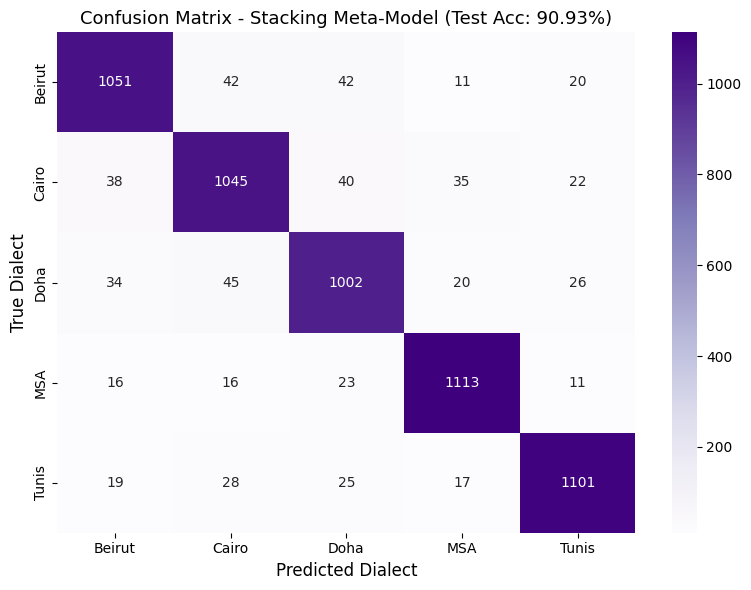

Best Classical Baseline artifacts saved successfully to Google Drive:
- Vectorizer : /content/drive/MyDrive/arabic-dialect-classification/models/baseline/refined_tfidf_vectorizer.joblib
- Model      : /content/drive/MyDrive/arabic-dialect-classification/models/baseline/stacking_baseline_model.joblib
- Test Report: /content/drive/MyDrive/arabic-dialect-classification/models/baseline/baseline_test_report.txt

Live Inference Sanity Check:
Predicted: [Cairo ] | Sentence: ازيك يا باشا عامل ايه النهارده
Predicted: [Tunis ] | Sentence: يعيشك خويا فماش تاكسي قريب من هنا
Predicted: [Beirut] | Sentence: شو بدك تاكل اليوم يا زلمه
Predicted: [Doha  ] | Sentence: انا ماشي فاصرف لي هالفيش لو سمحت
Predicted: [MSA   ] | Sentence: هل يمكنك ان تساعدني في العثور علي الفندق


In [12]:
import joblib

# 1. Plot Final Confusion Matrix for our best classical model (Stacking Classifier)
labels = sorted(y_test.unique())
cm_stack = confusion_matrix(y_test, test_pred_stack, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_stack, annot=True, fmt='d', cmap='Purples', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix - Stacking Meta-Model (Test Acc: {test_acc_stack:.2f}%)', fontsize=13)
plt.xlabel('Predicted Dialect', fontsize=12)
plt.ylabel('True Dialect', fontsize=12)
plt.tight_layout()
plt.show()

# 2. Save the Refined Vectorizer and the Winning Stacking Model to Google Drive
models_dir = '/content/drive/MyDrive/arabic-dialect-classification/models/baseline'
os.makedirs(models_dir, exist_ok=True)

vectorizer_path = os.path.join(models_dir, 'refined_tfidf_vectorizer.joblib')
model_path = os.path.join(models_dir, 'stacking_baseline_model.joblib')
metrics_path = os.path.join(models_dir, 'baseline_test_report.txt')

joblib.dump(refined_vectorizer, vectorizer_path)
joblib.dump(stacking_model, model_path)

with open(metrics_path, 'w') as f:
    f.write("Official Best Classical Model: StackingClassifier (MNB + CNB + LinearSVC + LR) + Word(1,2) & Char_wb(2,6) TF-IDF\n")
    f.write(f"Validation Accuracy : {val_acc_stack:.2f}%\n")
    f.write(f"Test Accuracy       : {test_acc_stack:.2f}%\n")
    f.write(f"Test Macro F1       : {test_f1_stack:.2f}%\n\n")
    f.write(classification_report(y_test, test_pred_stack, digits=4))

print("Best Classical Baseline artifacts saved successfully to Google Drive:")
print(f"- Vectorizer : {vectorizer_path}")
print(f"- Model      : {model_path}")
print(f"- Test Report: {metrics_path}\n")

# 3. Live Inference Sanity Check on 5 custom sentences (including tricky ones!)
test_samples = [
    "ازيك يا باشا عامل ايه النهارده",          # Expected: Cairo
    "يعيشك خويا فماش تاكسي قريب من هنا",       # Expected: Tunis
    "شو بدك تاكل اليوم يا زلمه",              # Expected: Beirut
    "انا ماشي فاصرف لي هالفيش لو سمحت",       # Expected: Doha (Fixed by Ensemble/Stacking!)
    "هل يمكنك ان تساعدني في العثور علي الفندق" # Expected: MSA
]

sample_features = refined_vectorizer.transform(test_samples)
sample_preds = stacking_model.predict(sample_features)

print("Live Inference Sanity Check:")
for sent, pred in zip(test_samples, sample_preds):
    print(f"Predicted: [{pred:6s}] | Sentence: {sent}")